# DER Orchestration & Dispatch Optimization Prototype

**Omni-Grid Renewable Energy Intelligence Platform**  
**Model:** DER Dispatch Optimizer v1.0  
**Component:** Component 7 — DER Orchestration & Dispatch Optimization  
**Prototype Type:** MPC-style optimizer + ML dispatch policy + real-time adjustment classifier

## Purpose
This notebook builds a detailed prototype for **DER Orchestration & Dispatch Optimization**. The goal is to optimize distributed solar and storage dispatch so the system can maximize revenue while maintaining safe grid operation.

The prototype includes:
1. Dataset loading and validation.
2. Dispatch-focused feature engineering.
3. Baseline dispatch policy.
4. MPC-style optimization policy.
5. Machine learning policy model to imitate optimized dispatch.
6. Real-time adjustment classifier.
7. Business impact evaluation.
8. Dispatch recommendation output.

## Important Prototype Assumption
The provided `synthetic-DODO-dataset.csv` is mainly an inverter telemetry and asset-health dataset. It contains useful fields such as inverter efficiency, rated capacity, temperature, voltage ripple, harmonic distortion, failure labels, restart counts, and error counts.

A full DER dispatch model would normally also need generation forecasts, market prices, battery SOC, grid constraints, and load profiles. Because those are not directly present in the dataset, this notebook creates a controlled synthetic dispatch layer from the available telemetry. In production, these simulated fields should be replaced by real SCADA, BMS, market, and grid-constraint data.

## 1. Import Libraries
This section imports the required libraries for data processing, modelling, evaluation, visualization, and saving outputs.

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import joblib
from IPython.display import display

pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 160)

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

## 2. Configure File Paths
The first path matches the project folder shown in the screenshot. The fallback paths allow the notebook to run if it is placed in the same folder as the CSV files.

In [ ]:
# ================================================================
# Data paths (portable)
# ================================================================
# Run this notebook from its own module folder. Data lives in ./data.
# If the full synthetic dataset is not present, the sample file is used
# so the notebook still runs end to end for anyone who clones the repo.

DATA_DIR = Path.cwd() / "data"
DATASET_PATH = DATA_DIR / "synthetic_der_dataset.csv"
SAMPLE_PATH = DATA_DIR / "synthetic_der_sample.csv"
DICTIONARY_PATH = DATA_DIR / "synthetic_der_data_dictionary.csv"

if not DATASET_PATH.exists():
    print(f"Full dataset not found, using sample file: {SAMPLE_PATH.name}")
    DATASET_PATH = SAMPLE_PATH

OUTPUT_DIR = Path.cwd() / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)
print("Dataset path:", DATASET_PATH)


## 3. Load Dataset, Sample, and Data Dictionary
The full dataset is used for training and evaluation. The dictionary is used to verify column meanings.

In [ ]:
df = pd.read_csv(DATASET_PATH)
dictionary = pd.read_csv(DICTIONARY_PATH)
sample_df = pd.read_csv(SAMPLE_PATH)

print("Dataset shape:", df.shape)
print("Sample dataset shape:", sample_df.shape)
print("Dictionary shape:", dictionary.shape)

display(df.head())
display(dictionary.head(12))

## 4. Initial Data Understanding
Dispatch systems are sensitive to data quality. This section checks timestamps, asset IDs, categorical values, missing values, and column types.

In [4]:
if "date" not in df.columns:
    raise ValueError("Expected a date column in the dataset.")

df["date"] = pd.to_datetime(df["date"], errors="coerce")
df = df.sort_values(["inverter_id", "date"]).reset_index(drop=True)

print("Date range:", df["date"].min(), "to", df["date"].max())
print("Number of unique inverters:", df["inverter_id"].nunique())
print("Manufacturers:", df["manufacturer"].unique())
print("Climate zones:", df["climate_zone"].unique())

summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique()
}).sort_values("missing_pct", ascending=False)

display(summary.head(20))

Date range: 2025-01-01 00:00:00 to 2025-12-31 00:00:00
Number of unique inverters: 120
Manufacturers: ['Fronius' 'SolarEdge' 'Huawei' 'SMA']
Climate zones: ['Temperate' 'Coastal' 'Hot-Dry' 'Humid-Subtropical']


,dtype,missing_count,missing_pct,unique_values
rul_days,float64,17155,52.58,366
date,datetime64[ns],0,0.00,365
fan_speed_rpm,float64,0,0.00,12295
restart_count_today,int64,0,0.00,9
error_code_count_today,int64,0,0.00,10
thermal_cycling_count_today,int64,0,0.00,13
overload_events_today,int64,0,0.00,9
failure_within_7d,int64,0,0.00,2
failure_within_30d,int64,0,0.00,2
failure_within_90d,int64,0,0.00,2


## 5. Exploratory Analysis
The dataset is asset-health focused, so we first inspect operational variables that can be converted into dispatch signals.

In [5]:
key_numeric_columns = [
    "rated_capacity_kw", "operating_hours_today", "efficiency_pct",
    "ambient_temperature_c", "internal_temperature_c", "voltage_ripple",
    "current_harmonic_distortion_pct", "reactive_power_capability",
    "failure_within_7d", "failure_within_30d", "failure_within_90d",
    "restart_7d_sum", "errors_7d_sum"
]

available_key_columns = [c for c in key_numeric_columns if c in df.columns]
display(df[available_key_columns].describe().T)

,count,mean,std,min,25%,50%,75%,max
rated_capacity_kw,32627.0,118.523769,69.349305,50.000,75.000,100.000,150.000,250.000
operating_hours_today,32627.0,11.506681,1.205308,6.490,10.700,11.510,12.330,15.000
efficiency_pct,32627.0,97.088746,1.994811,88.430,97.170,97.740,98.170,99.500
ambient_temperature_c,32627.0,25.010567,5.297533,1.670,21.450,25.000,28.580,45.050
internal_temperature_c,32627.0,36.222312,6.081014,20.000,32.090,36.110,40.180,63.220
voltage_ripple,32627.0,2.601263,0.763142,0.552,2.026,2.596,3.137,5.749
current_harmonic_distortion_pct,32627.0,5.165739,1.479057,1.096,4.051,5.173,6.225,10.754
reactive_power_capability,32627.0,0.981589,0.065462,0.675,0.946,0.988,1.026,1.100
failure_within_7d,32627.0,0.017869,0.132476,0.000,0.000,0.000,0.000,1.000
failure_within_30d,32627.0,0.069329,0.254017,0.000,0.000,0.000,0.000,1.000


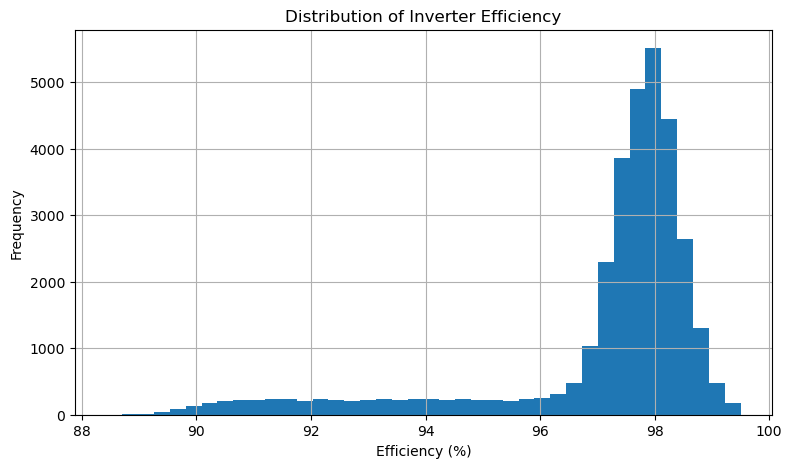

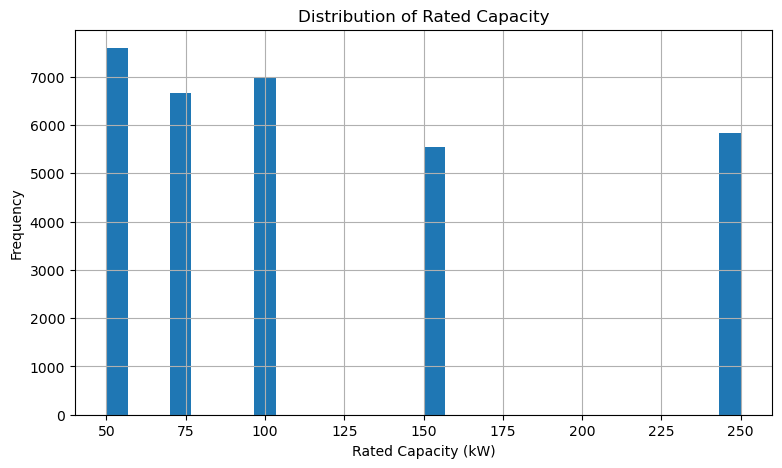

In [6]:
plt.figure(figsize=(9, 5))
df["efficiency_pct"].hist(bins=40)
plt.title("Distribution of Inverter Efficiency")
plt.xlabel("Efficiency (%)")
plt.ylabel("Frequency")
plt.show()

plt.figure(figsize=(9, 5))
df["rated_capacity_kw"].hist(bins=30)
plt.title("Distribution of Rated Capacity")
plt.xlabel("Rated Capacity (kW)")
plt.ylabel("Frequency")
plt.show()

## 6. Data Quality Preparation
Numeric missing values are filled using medians. Categorical missing values are filled as `Unknown`. This keeps the prototype robust without dropping large sections of telemetry.

In [7]:
work_df = df.copy()
work_df = work_df.dropna(subset=["date", "inverter_id"])

categorical_columns = work_df.select_dtypes(include=["object"]).columns.tolist()
for col in categorical_columns:
    work_df[col] = work_df[col].fillna("Unknown")

numeric_columns = work_df.select_dtypes(include=[np.number]).columns.tolist()
for col in numeric_columns:
    work_df[col] = work_df[col].fillna(work_df[col].median())

print("Remaining missing values:", int(work_df.isna().sum().sum()))
print("Prepared dataset shape:", work_df.shape)

Remaining missing values: 0
Prepared dataset shape: (32627, 42)


## 7. DER Dispatch Feature Engineering
The raw dataset does not contain direct dispatch variables such as battery SOC, market price, local demand, or grid export limits. This section creates a synthetic dispatch layer using inverter telemetry and asset-health signals.

Main engineered features:
- `available_solar_mwh`: estimated daily solar energy available for dispatch.
- `failure_risk_score`: operational risk derived from failure labels, RUL, restarts, and errors.
- `grid_stress_score`: power-quality risk derived from voltage ripple, harmonics, thermal stress, overload events, and reactive power capability.
- `battery_capacity_mwh` and `initial_soc_mwh`: battery availability proxy.
- `market_price_aud_mwh`: synthetic market price proxy.
- `grid_export_limit_mwh`: synthetic network export limit.

In [8]:
def minmax_scale(series: pd.Series) -> pd.Series:
    """Safely min-max scale a numeric series into the 0-1 range."""
    return (series - series.min()) / (series.max() - series.min() + 1e-9)

# Temporal features
work_df["month"] = work_df["date"].dt.month
work_df["day_of_week"] = work_df["date"].dt.dayofweek
work_df["is_weekend"] = work_df["day_of_week"].isin([5, 6]).astype(int)
work_df["season_sin"] = np.sin(2 * np.pi * work_df["month"] / 12)
work_df["season_cos"] = np.cos(2 * np.pi * work_df["month"] / 12)

# Estimate available daily solar energy in MWh.
weather_derate = (
    1
    - 0.08 * work_df["dust_soiling_index"]
    - 0.002 * np.maximum(work_df["ambient_temperature_c"] - 25, 0)
)
weather_derate = np.clip(weather_derate, 0.70, 1.02)

work_df["available_solar_mwh"] = (
    work_df["rated_capacity_kw"]
    * work_df["operating_hours_today"]
    * (work_df["efficiency_pct"] / 100)
    * weather_derate
) / 1000

# Failure risk proxy.
rul_safe = work_df["rul_days"].fillna(999)
work_df["failure_risk_score"] = np.clip(
    0.45 * work_df["failure_within_30d"]
    + 0.20 * work_df["failure_within_90d"]
    + 0.15 * minmax_scale(work_df["errors_7d_sum"])
    + 0.10 * minmax_scale(work_df["restart_7d_sum"])
    + 0.10 * (1 - minmax_scale(rul_safe)),
    0, 1
)

# Grid stress proxy.
work_df["grid_stress_score"] = np.clip(
    0.25 * minmax_scale(work_df["voltage_ripple"])
    + 0.25 * minmax_scale(work_df["current_harmonic_distortion_pct"])
    + 0.20 * minmax_scale(work_df["temp_stress_index"])
    + 0.15 * minmax_scale(work_df["overload_events_today"])
    + 0.15 * (1 - minmax_scale(work_df["reactive_power_capability"])),
    0, 1
)

# Asset health score.
work_df["asset_health_score"] = np.clip(
    1 - (
        0.50 * work_df["failure_risk_score"]
        + 0.30 * work_df["capacitor_degradation_indicator"]
        + 0.20 * minmax_scale(work_df["efficiency_decline_7d"].abs())
    ),
    0, 1
)

# Synthetic grid export limit.
work_df["grid_export_limit_mwh"] = np.maximum(
    work_df["rated_capacity_kw"] * work_df["operating_hours_today"] / 1000 * (1.30 - 0.25 * work_df["grid_stress_score"]),
    work_df["rated_capacity_kw"] * 2.0 / 1000
)

# Synthetic battery variables.
work_df["battery_capacity_mwh"] = work_df["rated_capacity_kw"] * 7.0 / 1000
work_df["initial_soc_mwh"] = np.clip(
    work_df["battery_capacity_mwh"] * (
        0.55 + 0.16 * work_df["season_sin"] - 0.10 * work_df["failure_risk_score"] + rng.normal(0, 0.06, len(work_df))
    ),
    work_df["battery_capacity_mwh"] * 0.10,
    work_df["battery_capacity_mwh"] * 0.95
)
work_df["max_charge_mwh"] = work_df["battery_capacity_mwh"] * 0.50
work_df["max_discharge_mwh"] = work_df["battery_capacity_mwh"] * 0.50

# Synthetic energy price in AUD/MWh.
work_df["market_price_aud_mwh"] = np.clip(
    72
    + 8 * np.where(work_df["month"].isin([6, 7, 8, 12, 1, 2]), 1, 0)
    + 0.50 * np.maximum(work_df["ambient_temperature_c"] - 22, 0)
    + 25 * work_df["grid_stress_score"]
    + 15 * np.sin(2 * np.pi * work_df["day_of_week"] / 7)
    + rng.normal(0, 8, len(work_df)),
    25, 220
)

# Local load proxy for future extension.
work_df["local_load_demand_mwh"] = np.clip(
    0.45 * work_df["available_solar_mwh"]
    + 0.20 * work_df["battery_capacity_mwh"]
    + 0.10 * work_df["grid_stress_score"]
    + rng.normal(0, 0.03, len(work_df)),
    0, None
)

engineered_columns = [
    "available_solar_mwh", "failure_risk_score", "grid_stress_score", "asset_health_score",
    "grid_export_limit_mwh", "battery_capacity_mwh", "initial_soc_mwh",
    "max_charge_mwh", "max_discharge_mwh", "market_price_aud_mwh", "local_load_demand_mwh"
]

display(work_df[engineered_columns].describe().T)

,count,mean,std,min,25%,50%,75%,max
available_solar_mwh,32627.0,1.272748,0.759882,0.341414,0.685372,1.012416,1.651751,3.597474
failure_risk_score,32627.0,0.162348,0.211119,0.000548,0.073756,0.078964,0.091464,0.962145
grid_stress_score,32627.0,0.263853,0.098022,0.043947,0.193798,0.254037,0.315762,0.794188
asset_health_score,32627.0,0.744965,0.148830,0.087063,0.738723,0.794177,0.828049,0.946626
grid_export_limit_mwh,32627.0,1.683154,1.005503,0.456363,0.908746,1.338170,2.184679,4.820637
battery_capacity_mwh,32627.0,0.829666,0.485445,0.350000,0.525000,0.700000,1.050000,1.750000
initial_soc_mwh,32627.0,0.461791,0.297935,0.063997,0.236377,0.366465,0.611904,1.541529
max_charge_mwh,32627.0,0.414833,0.242723,0.175000,0.262500,0.350000,0.525000,0.875000
max_discharge_mwh,32627.0,0.414833,0.242723,0.175000,0.262500,0.350000,0.525000,0.875000
market_price_aud_mwh,32627.0,84.638218,14.326445,36.910893,74.070959,84.724677,95.088227,141.645799


## 8. Baseline Dispatch Policy
The baseline policy represents a simple export-only approach:
- export available solar up to the grid limit,
- curtail excess solar,
- do not optimize battery charge/discharge,
- do not respond to market price signals.

In [9]:
work_df["baseline_grid_export_mwh"] = np.minimum(work_df["available_solar_mwh"], work_df["grid_export_limit_mwh"])
work_df["baseline_curtailment_mwh"] = np.maximum(work_df["available_solar_mwh"] - work_df["baseline_grid_export_mwh"], 0)
work_df["baseline_revenue_aud"] = (
    work_df["market_price_aud_mwh"] * work_df["baseline_grid_export_mwh"]
    - 25 * work_df["baseline_curtailment_mwh"]
    - 12 * work_df["grid_stress_score"] * work_df["baseline_grid_export_mwh"]
)

baseline_summary = pd.Series({
    "baseline_total_revenue_aud": work_df["baseline_revenue_aud"].sum(),
    "baseline_total_export_mwh": work_df["baseline_grid_export_mwh"].sum(),
    "baseline_total_curtailment_mwh": work_df["baseline_curtailment_mwh"].sum(),
    "baseline_avg_revenue_per_row_aud": work_df["baseline_revenue_aud"].mean()
})
display(baseline_summary.to_frame("value"))

,value
baseline_total_revenue_aud,3.380633e+06
baseline_total_export_mwh,4.152597e+04
baseline_total_curtailment_mwh,0.000000e+00
baseline_avg_revenue_per_row_aud,1.036146e+02


## 9. MPC-Style Optimization Layer
This section creates a transparent optimization policy inspired by Model Predictive Control.

For each asset-day, the optimizer decides:
- battery charge MWh,
- battery discharge MWh,
- grid export MWh,
- curtailment MWh,
- ending battery SOC.

Objective: maximize market revenue while penalizing curtailment, grid stress, and violations.

Constraints:
- grid export limit,
- battery SOC limits,
- minimum SOC reserve,
- maximum charge and discharge limits,
- reduced battery aggressiveness for high-risk assets.

In [11]:
def mpc_dispatch_policy(row: pd.Series) -> pd.Series:
    """Simplified MPC-style dispatch optimizer for one asset-day."""
    eta_charge = 0.95
    eta_discharge = 0.92

    available = row["available_solar_mwh"]
    export_limit = row["grid_export_limit_mwh"]
    battery_cap = row["battery_capacity_mwh"]
    soc_start = row["initial_soc_mwh"]
    price = row["market_price_aud_mwh"]
    grid_stress = row["grid_stress_score"]
    failure_risk = row["failure_risk_score"]

    reserve_min = battery_cap * (0.12 + 0.08 * grid_stress)
    max_charge = max(min(row["max_charge_mwh"], battery_cap - soc_start), 0)
    max_discharge = max(min(row["max_discharge_mwh"], soc_start - reserve_min) * (1 - 0.30 * failure_risk), 0)

    direct_export_no_battery = min(available, export_limit)
    surplus_solar = max(available - direct_export_no_battery, 0)

    low_price_charge = max(0, (70 - price) / 70) * available * 0.30
    stress_charge = max(0, grid_stress - 0.70) * available * 0.05
    charge_mwh = min(max_charge, surplus_solar + low_price_charge + stress_charge)

    direct_export = min(max(available - charge_mwh, 0), export_limit)

    price_signal = np.clip((price - 70) / 50, 0, 1)
    discharge_mwh = min(max_discharge, max(export_limit - direct_export, 0), price_signal * row["max_discharge_mwh"])

    grid_export_mwh = min(direct_export + discharge_mwh, export_limit)
    curtailment_mwh = max(available - charge_mwh - direct_export, 0)

    soc_end_mwh = np.clip(soc_start + eta_charge * charge_mwh - discharge_mwh / eta_discharge, 0, battery_cap)

    grid_violation = int(
        (grid_export_mwh > export_limit + 1e-6)
        or (soc_end_mwh < -1e-6)
        or (soc_end_mwh > battery_cap + 1e-6)
    )

    revenue_aud = (
        price * grid_export_mwh
        - 25 * curtailment_mwh
        - 12 * grid_stress * grid_export_mwh
        - 200 * grid_violation
    )

    return pd.Series({
        "opt_charge_mwh": charge_mwh,
        "opt_discharge_mwh": discharge_mwh,
        "opt_grid_export_mwh": grid_export_mwh,
        "opt_curtailment_mwh": curtailment_mwh,
        "opt_soc_end_mwh": soc_end_mwh,
        "opt_revenue_aud": revenue_aud,
        "opt_grid_violation": grid_violation
    })

optimized_outputs = work_df.apply(mpc_dispatch_policy, axis=1)
work_df = pd.concat([work_df, optimized_outputs], axis=1)

display(work_df[[
    "date", "inverter_id", "available_solar_mwh", "market_price_aud_mwh", "grid_export_limit_mwh",
    "initial_soc_mwh", "opt_charge_mwh", "opt_discharge_mwh", "opt_grid_export_mwh",
    "opt_curtailment_mwh", "opt_revenue_aud", "opt_grid_violation"
]].head())

,date,inverter_id,available_solar_mwh,market_price_aud_mwh,grid_export_limit_mwh,initial_soc_mwh,opt_charge_mwh,opt_charge_mwh,opt_discharge_mwh,opt_discharge_mwh,opt_grid_export_mwh,opt_grid_export_mwh,opt_curtailment_mwh,opt_curtailment_mwh,opt_revenue_aud,opt_revenue_aud,opt_grid_violation,opt_grid_violation
0,2025-01-01,INV-0001,1.126667,102.940652,1.464431,0.449234,0.000000,0.000000,0.230585,0.230585,1.357252,1.357252,0.0,0.0,136.012707,136.012707,0.0,0.0
1,2025-01-02,INV-0001,1.165576,89.319229,1.531433,0.392737,0.000000,0.000000,0.135235,0.135235,1.300811,1.300811,0.0,0.0,112.757517,112.757517,0.0,0.0
2,2025-01-03,INV-0001,1.177971,82.812129,1.515749,0.467916,0.000000,0.000000,0.089685,0.089685,1.267656,1.267656,0.0,0.0,100.615881,100.615881,0.0,0.0
3,2025-01-04,INV-0001,0.999667,63.825649,1.290703,0.475882,0.026453,0.026453,0.000000,0.000000,0.973214,0.973214,0.0,0.0,59.307023,59.307023,0.0,0.0
4,2025-01-05,INV-0001,1.400502,73.053847,1.800928,0.354415,0.000000,0.000000,0.021377,0.021377,1.421879,1.421879,0.0,0.0,98.991400,98.991400,0.0,0.0


## 10. Baseline vs Optimized Dispatch Impact
This checks whether the optimized policy improves revenue while keeping grid violations at zero.

In [ ]:
impact_summary = pd.Series({
    "baseline_total_revenue_aud": work_df["baseline_revenue_aud"].sum(),
    "optimized_total_revenue_aud": work_df["opt_revenue_aud"].sum(),
    "revenue_uplift_pct": (work_df["opt_revenue_aud"].sum() / work_df["baseline_revenue_aud"].sum() - 1) * 100,
    "baseline_total_export_mwh": work_df["baseline_grid_export_mwh"].sum(),
    "optimized_total_export_mwh": work_df["opt_grid_export_mwh"].sum(),
    "baseline_total_curtailment_mwh": work_df["baseline_curtailment_mwh"].sum(),
    "optimized_total_curtailment_mwh": work_df["opt_curtailment_mwh"].sum(),
    "optimized_grid_violations": work_df["opt_grid_violation"].sum()
})
display(impact_summary.to_frame("value"))

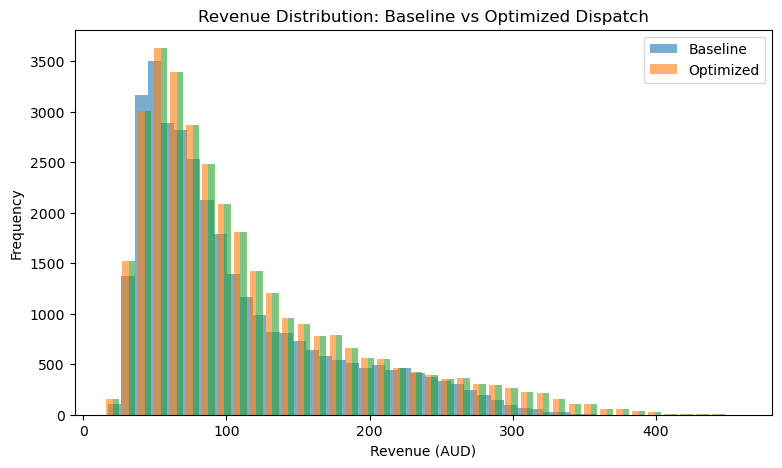

Scatter plot data shape: (32627, 2)


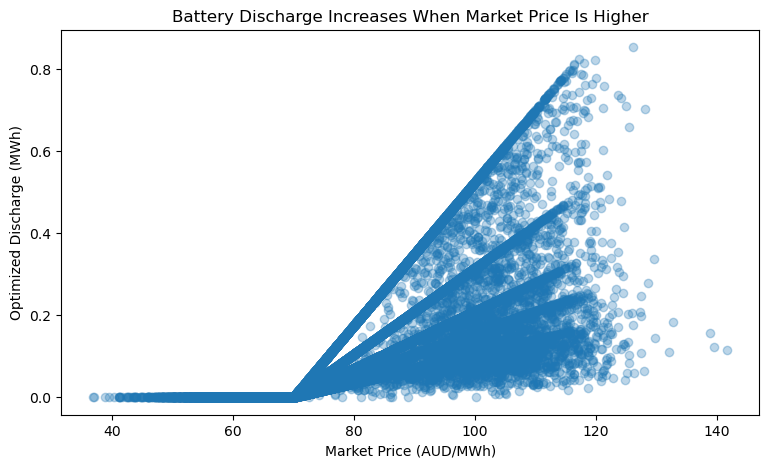

In [14]:
# Revenue distribution: baseline vs optimized dispatch

plt.figure(figsize=(9, 5))
plt.hist(work_df["baseline_revenue_aud"], bins=40, alpha=0.6, label="Baseline")
plt.hist(work_df["opt_revenue_aud"], bins=40, alpha=0.6, label="Optimized")
plt.title("Revenue Distribution: Baseline vs Optimized Dispatch")
plt.xlabel("Revenue (AUD)")
plt.ylabel("Frequency")
plt.legend()
plt.show()


# Fix duplicate column names before scatter plot
work_df = work_df.loc[:, ~work_df.columns.duplicated()].copy()

# Scatter plot: Market price vs optimized battery discharge
scatter_df = work_df[["market_price_aud_mwh", "opt_discharge_mwh"]].copy()

scatter_df["market_price_aud_mwh"] = pd.to_numeric(
    scatter_df["market_price_aud_mwh"], errors="coerce"
)

scatter_df["opt_discharge_mwh"] = pd.to_numeric(
    scatter_df["opt_discharge_mwh"], errors="coerce"
)

scatter_df = scatter_df.dropna(subset=["market_price_aud_mwh", "opt_discharge_mwh"])

print("Scatter plot data shape:", scatter_df.shape)

plt.figure(figsize=(9, 5))
plt.scatter(
    scatter_df["market_price_aud_mwh"].values,
    scatter_df["opt_discharge_mwh"].values,
    alpha=0.3
)
plt.title("Battery Discharge Increases When Market Price Is Higher")
plt.xlabel("Market Price (AUD/MWh)")
plt.ylabel("Optimized Discharge (MWh)")
plt.show()

## 11. Time-Based Train-Test Split
The model is evaluated on later dates to imitate real operational forecasting and dispatch deployment.

In [15]:
feature_columns = [
    "manufacturer", "climate_zone", "rated_capacity_kw", "installation_quality_score",
    "maintenance_quality_score", "age_months", "ambient_temperature_c", "humidity_pct",
    "dust_soiling_index", "uv_exposure_index", "operating_hours_today", "efficiency_pct",
    "reactive_power_capability", "internal_temperature_c", "voltage_ripple",
    "current_harmonic_distortion_pct", "insulation_resistance_mohm", "capacitor_degradation_indicator",
    "fan_speed_rpm", "restart_count_today", "error_code_count_today", "thermal_cycling_count_today",
    "overload_events_today", "efficiency_7d_mean", "efficiency_30d_mean", "temperature_7d_mean",
    "temperature_30d_mean", "efficiency_decline_7d", "temp_stress_index", "restart_7d_sum",
    "errors_7d_sum", "month", "day_of_week", "is_weekend", "season_sin", "season_cos",
    "available_solar_mwh", "failure_risk_score", "grid_stress_score", "asset_health_score",
    "grid_export_limit_mwh", "battery_capacity_mwh", "initial_soc_mwh", "market_price_aud_mwh",
    "local_load_demand_mwh"
]

target_columns = ["opt_charge_mwh", "opt_discharge_mwh", "opt_grid_export_mwh", "opt_curtailment_mwh"]

split_date = work_df["date"].quantile(0.80)
train_mask = work_df["date"] <= split_date

X_train = work_df.loc[train_mask, feature_columns]
y_train = work_df.loc[train_mask, target_columns]
X_test = work_df.loc[~train_mask, feature_columns]
y_test = work_df.loc[~train_mask, target_columns]
test_context = work_df.loc[~train_mask].copy().reset_index(drop=True)

print("Split date:", split_date)
print("Training shape:", X_train.shape, y_train.shape)
print("Testing shape:", X_test.shape, y_test.shape)

Split date: 2025-09-12 00:00:00
Training shape: (26166, 45) (26166, 4)
Testing shape: (6461, 45) (6461, 4)


## 12. ML Dispatch Policy Model
The optimized MPC policy is useful, but production systems often need fast inference. Therefore, we train a supervised ML model to imitate the optimized policy.

The model predicts four actions:
1. battery charge MWh,
2. battery discharge MWh,
3. grid export MWh,
4. curtailment MWh.

In [16]:
categorical_features = ["manufacturer", "climate_zone"]
numeric_features = [c for c in feature_columns if c not in categorical_features]

try:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", encoder, categorical_features),
        ("numeric", StandardScaler(), numeric_features)
    ]
)

dispatch_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=40,
        max_depth=12,
        min_samples_leaf=3,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

dispatch_model.fit(X_train, y_train)
print("Dispatch policy model training complete.")

Dispatch policy model training complete.


## 13. Dispatch Model Evaluation
The key regression metrics are MAE, RMSE, and R² for each dispatch action.

In [17]:
y_pred = dispatch_model.predict(X_test)
y_pred_df = pd.DataFrame(y_pred, columns=["pred_" + c.replace("opt_", "") for c in target_columns])

regression_metrics = []
for i, target in enumerate(target_columns):
    actual = y_test.iloc[:, i]
    pred = y_pred[:, i]
    regression_metrics.append({
        "target": target,
        "MAE": mean_absolute_error(actual, pred),
        "RMSE": mean_squared_error(actual, pred) ** 0.5,
        "R2": r2_score(actual, pred)
    })

regression_metrics_df = pd.DataFrame(regression_metrics)
display(regression_metrics_df)

,target,MAE,RMSE,R2
0,opt_charge_mwh,0.000746,0.004346,0.971938
1,opt_discharge_mwh,0.006327,0.017831,0.978267
2,opt_grid_export_mwh,0.008491,0.020330,0.999428
3,opt_curtailment_mwh,0.000000,0.000000,1.000000


## 14. Feasibility Post-Processing
Machine learning predictions must be checked before use. This function clips predicted actions so they respect battery and grid constraints.

In [18]:
def evaluate_predicted_policy(test_rows: pd.DataFrame, predictions: np.ndarray) -> pd.DataFrame:
    """Convert raw ML predictions into feasible dispatch actions and calculate revenue."""
    eta_charge = 0.95
    eta_discharge = 0.92

    charge = np.maximum(predictions[:, 0], 0)
    discharge = np.maximum(predictions[:, 1], 0)

    max_charge = np.minimum(
        test_rows["max_charge_mwh"].values,
        np.maximum(test_rows["battery_capacity_mwh"].values - test_rows["initial_soc_mwh"].values, 0)
    )
    charge = np.minimum(charge, max_charge)

    reserve_min = test_rows["battery_capacity_mwh"].values * (0.12 + 0.08 * test_rows["grid_stress_score"].values)
    max_discharge = np.minimum(
        test_rows["max_discharge_mwh"].values,
        np.maximum(test_rows["initial_soc_mwh"].values - reserve_min, 0)
    ) * (1 - 0.30 * test_rows["failure_risk_score"].values)
    discharge = np.minimum(discharge, max_discharge)

    direct_export = np.minimum(
        np.maximum(test_rows["available_solar_mwh"].values - charge, 0),
        test_rows["grid_export_limit_mwh"].values
    )
    grid_export = np.minimum(direct_export + discharge, test_rows["grid_export_limit_mwh"].values)
    curtailment = np.maximum(test_rows["available_solar_mwh"].values - charge - direct_export, 0)
    soc_end = np.clip(
        test_rows["initial_soc_mwh"].values + eta_charge * charge - discharge / eta_discharge,
        0,
        test_rows["battery_capacity_mwh"].values
    )

    violations = (
        (grid_export > test_rows["grid_export_limit_mwh"].values + 1e-6)
        | (soc_end < -1e-6)
        | (soc_end > test_rows["battery_capacity_mwh"].values + 1e-6)
    ).astype(int)

    revenue = (
        test_rows["market_price_aud_mwh"].values * grid_export
        - 25 * curtailment
        - 12 * test_rows["grid_stress_score"].values * grid_export
        - 200 * violations
    )

    return pd.DataFrame({
        "model_charge_mwh": charge,
        "model_discharge_mwh": discharge,
        "model_grid_export_mwh": grid_export,
        "model_curtailment_mwh": curtailment,
        "model_soc_end_mwh": soc_end,
        "model_grid_violation": violations,
        "model_revenue_aud": revenue
    })

model_policy = evaluate_predicted_policy(test_context, y_pred)
display(model_policy.head())

,model_charge_mwh,model_discharge_mwh,model_grid_export_mwh,model_curtailment_mwh,model_soc_end_mwh,model_grid_violation,model_revenue_aud
0,0.011267,0.000000,0.598113,0.0,0.118483,0,37.288421
1,0.030513,0.000000,0.559639,0.0,0.129425,0,30.098770
2,0.000000,0.065520,0.597370,0.0,0.046170,0,57.834500
3,0.000000,0.079175,0.531740,0.0,0.057236,0,48.939916
4,0.000000,0.078439,0.739086,0.0,0.059648,0,68.488273


## 15. Business Impact Evaluation on Test Data
This compares baseline dispatch, optimized dispatch, and ML policy dispatch.

The PRD target for this component is approximately **10–15% revenue increase vs baseline dispatch** while maintaining zero grid violations. Since this is a synthetic prototype, results should be interpreted as simulation outcomes rather than production claims.

In [19]:
baseline_test_revenue = test_context["baseline_revenue_aud"].sum()
optimized_test_revenue = test_context["opt_revenue_aud"].sum()
model_test_revenue = model_policy["model_revenue_aud"].sum()

business_impact = pd.Series({
    "baseline_test_revenue_aud": baseline_test_revenue,
    "optimized_test_revenue_aud": optimized_test_revenue,
    "ml_policy_test_revenue_aud": model_test_revenue,
    "optimized_uplift_vs_baseline_pct": (optimized_test_revenue / baseline_test_revenue - 1) * 100,
    "ml_policy_uplift_vs_baseline_pct": (model_test_revenue / baseline_test_revenue - 1) * 100,
    "baseline_test_export_mwh": test_context["baseline_grid_export_mwh"].sum(),
    "optimized_test_export_mwh": test_context["opt_grid_export_mwh"].sum(),
    "ml_policy_test_export_mwh": model_policy["model_grid_export_mwh"].sum(),
    "optimized_grid_violations": test_context["opt_grid_violation"].sum(),
    "ml_policy_grid_violations": model_policy["model_grid_violation"].sum()
})

display(business_impact.to_frame("value"))

,value
baseline_test_revenue_aud,665308.305167
optimized_test_revenue_aud,724187.945183
ml_policy_test_revenue_aud,723337.447006
optimized_uplift_vs_baseline_pct,8.849978
ml_policy_uplift_vs_baseline_pct,8.722143
baseline_test_export_mwh,8388.684968
optimized_test_export_mwh,9022.012051
ml_policy_test_export_mwh,9014.006177
optimized_grid_violations,0.000000
ml_policy_grid_violations,0.000000


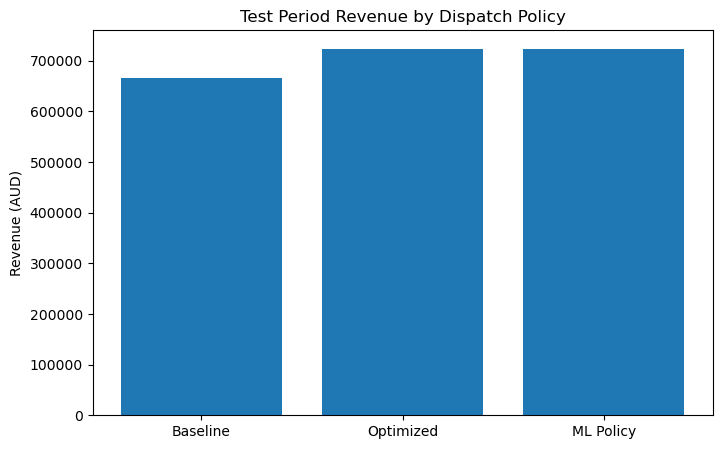

In [20]:
comparison_plot = pd.DataFrame({
    "policy": ["Baseline", "Optimized", "ML Policy"],
    "revenue_aud": [baseline_test_revenue, optimized_test_revenue, model_test_revenue]
})

plt.figure(figsize=(8, 5))
plt.bar(comparison_plot["policy"], comparison_plot["revenue_aud"])
plt.title("Test Period Revenue by Dispatch Policy")
plt.ylabel("Revenue (AUD)")
plt.show()

## 16. Real-Time Adjustment Classifier
Full SAC/TD3 reinforcement learning requires a digital twin environment. For this prototype, we create a practical classifier to identify when dispatch should be adjusted in real time due to grid stress, failure risk, export-limit pressure, or thermal stress.

In [21]:
work_df["rt_adjustment_required"] = (
    (work_df["grid_stress_score"] >= 0.65)
    | (work_df["failure_risk_score"] >= 0.65)
    | (work_df["available_solar_mwh"] >= 0.95 * work_df["grid_export_limit_mwh"])
    | (work_df["temp_stress_index"] > work_df["temp_stress_index"].quantile(0.85))
).astype(int)

X_rt = work_df[feature_columns]
y_rt = work_df["rt_adjustment_required"]

X_rt_train = X_rt.loc[train_mask]
y_rt_train = y_rt.loc[train_mask]
X_rt_test = X_rt.loc[~train_mask]
y_rt_test = y_rt.loc[~train_mask]

rt_classifier = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=40,
        max_depth=12,
        min_samples_leaf=3,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        class_weight="balanced"
    ))
])

rt_classifier.fit(X_rt_train, y_rt_train)
rt_pred = rt_classifier.predict(X_rt_test)

print("Real-Time Adjustment Classifier Evaluation")
print("Accuracy:", round(accuracy_score(y_rt_test, rt_pred), 4))
print("Precision:", round(precision_score(y_rt_test, rt_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_rt_test, rt_pred, zero_division=0), 4))
print("F1:", round(f1_score(y_rt_test, rt_pred, zero_division=0), 4))
print("\nClassification Report:")
print(classification_report(y_rt_test, rt_pred, zero_division=0))
print("Confusion Matrix:")
print(confusion_matrix(y_rt_test, rt_pred))

Real-Time Adjustment Classifier Evaluation
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1: 1.0

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      5130
           1       1.00      1.00      1.00      1331

    accuracy                           1.00      6461
   macro avg       1.00      1.00      1.00      6461
weighted avg       1.00      1.00      1.00      6461

Confusion Matrix:
[[5130    0]
 [   0 1331]]


## 17. Model Interpretability
Feature importance helps explain which variables most influence dispatch decisions. In production, this should be expanded with SHAP values and formal model cards.

,feature,importance
42,numeric__available_solar_mwh,0.951420
49,numeric__market_price_aud_mwh,0.035794
50,numeric__local_load_demand_mwh,0.008507
46,numeric__grid_export_limit_mwh,0.002040
48,numeric__initial_soc_mwh,0.001641
16,numeric__operating_hours_today,0.000227
47,numeric__battery_capacity_mwh,0.000074
8,numeric__rated_capacity_kw,0.000020
45,numeric__asset_health_score,0.000018
23,numeric__capacitor_degradation_indicator,0.000017


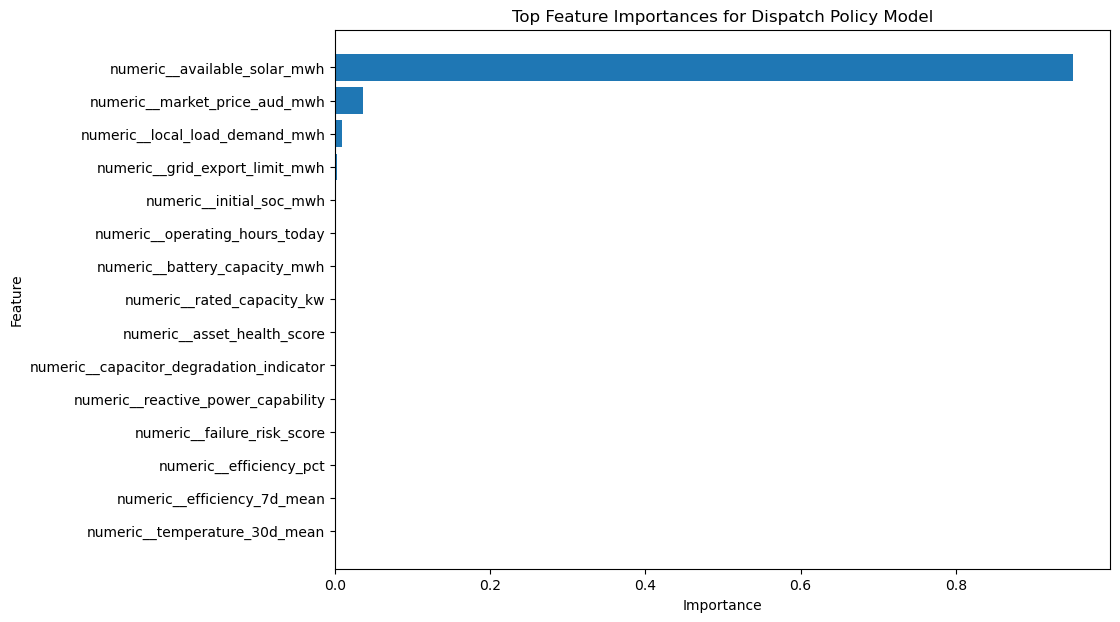

In [22]:
feature_names = dispatch_model.named_steps["preprocessor"].get_feature_names_out()
importances = dispatch_model.named_steps["model"].feature_importances_

importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
}).sort_values("importance", ascending=False)

display(importance_df.head(20))

plt.figure(figsize=(10, 7))
top_importance = importance_df.head(15).sort_values("importance")
plt.barh(top_importance["feature"], top_importance["importance"])
plt.title("Top Feature Importances for Dispatch Policy Model")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

## 18. Dispatch Recommendation Output
This creates a recommendation table suitable for dashboards, API responses, or manager review.

In [23]:
recommendations = pd.concat([
    test_context[[
        "date", "inverter_id", "manufacturer", "climate_zone",
        "available_solar_mwh", "market_price_aud_mwh", "grid_export_limit_mwh",
        "initial_soc_mwh", "battery_capacity_mwh", "failure_risk_score",
        "grid_stress_score", "asset_health_score"
    ]].reset_index(drop=True),
    model_policy.reset_index(drop=True)
], axis=1)

recommendations["risk_level"] = pd.cut(
    recommendations[["failure_risk_score", "grid_stress_score"]].max(axis=1),
    bins=[-0.01, 0.25, 0.50, 0.75, 1.00],
    labels=["LOW", "MODERATE", "HIGH", "CRITICAL"]
)

recommendations["recommended_action"] = np.select(
    [
        recommendations["model_grid_violation"] == 1,
        recommendations["risk_level"].astype(str).eq("CRITICAL"),
        recommendations["model_discharge_mwh"] > recommendations["model_charge_mwh"],
        recommendations["model_charge_mwh"] > 0,
        recommendations["model_curtailment_mwh"] > 0
    ],
    [
        "BLOCK_DISPATCH_AND_REVIEW_CONSTRAINTS",
        "REDUCE_EXPORT_AND_REQUEST_OPERATOR_REVIEW",
        "DISCHARGE_BATTERY_AND_EXPORT_TO_GRID",
        "CHARGE_BATTERY_OR_LIMIT_EXPORT",
        "CURTAIL_EXCESS_SOLAR"
    ],
    default="NORMAL_EXPORT"
)

recommendations = recommendations.sort_values(["date", "inverter_id"]).reset_index(drop=True)
display(recommendations.head(15))

,date,inverter_id,manufacturer,climate_zone,available_solar_mwh,market_price_aud_mwh,grid_export_limit_mwh,initial_soc_mwh,battery_capacity_mwh,failure_risk_score,grid_stress_score,asset_health_score,model_charge_mwh,model_discharge_mwh,model_grid_export_mwh,model_curtailment_mwh,model_soc_end_mwh,model_grid_violation,model_revenue_aud,risk_level,recommended_action
0,2025-09-13,INV-0002,SolarEdge,Coastal,0.609380,65.442191,0.801185,0.107780,0.350,0.069589,0.258228,0.780477,0.011267,0.000000,0.598113,0.0,0.118483,0,37.288421,MODERATE,CHARGE_BATTERY_OR_LIMIT_EXPORT
1,2025-09-13,INV-0003,Huawei,Hot-Dry,0.865096,73.322675,1.253021,0.231767,0.700,0.366016,0.217810,0.607897,0.000000,0.020255,0.885352,0.0,0.209750,0,62.602290,MODERATE,DISCHARGE_BATTERY_AND_EXPORT_TO_GRID
2,2025-09-13,INV-0004,SMA,Coastal,0.852520,71.851446,1.143622,0.203840,0.525,0.083131,0.220966,0.800809,0.000041,0.011149,0.863628,0.0,0.191759,0,59.762964,LOW,DISCHARGE_BATTERY_AND_EXPORT_TO_GRID
3,2025-09-13,INV-0007,SolarEdge,Coastal,2.081805,78.202244,2.798477,0.638580,1.750,0.082610,0.208290,0.823055,0.000075,0.149598,2.231328,0.0,0.476044,0,168.917699,LOW,DISCHARGE_BATTERY_AND_EXPORT_TO_GRID
4,2025-09-13,INV-0008,Fronius,Coastal,0.592747,66.987141,0.767614,0.104938,0.350,0.074277,0.341683,0.817229,0.006311,0.000223,0.586658,0.0,0.110692,0,36.893154,MODERATE,CHARGE_BATTERY_OR_LIMIT_EXPORT
5,2025-09-13,INV-0009,SMA,Humid-Subtropical,0.812471,78.714624,1.034530,0.182901,0.525,0.094752,0.269265,0.742009,0.000000,0.046994,0.859465,0.0,0.131821,0,64.875373,MODERATE,DISCHARGE_BATTERY_AND_EXPORT_TO_GRID
6,2025-09-13,INV-0011,SolarEdge,Coastal,1.569475,65.717572,2.048439,0.423832,1.050,0.077922,0.160789,0.793524,0.027117,0.000000,1.542357,0.0,0.449593,0,98.384065,LOW,CHARGE_BATTERY_OR_LIMIT_EXPORT
7,2025-09-13,INV-0016,Huawei,Humid-Subtropical,0.510699,71.959335,0.699870,0.080545,0.350,0.888460,0.514677,0.216529,0.000133,0.006414,0.516980,0.0,0.073700,0,34.008593,CRITICAL,REDUCE_EXPORT_AND_REQUEST_OPERATOR_REVIEW
8,2025-09-13,INV-0017,Fronius,Coastal,0.774207,75.755317,1.045566,0.208412,0.525,0.378350,0.421633,0.550262,0.000000,0.031797,0.806005,0.0,0.173850,0,56.981072,MODERATE,DISCHARGE_BATTERY_AND_EXPORT_TO_GRID
9,2025-09-13,INV-0018,SMA,Coastal,0.771385,69.839602,1.003509,0.224740,0.525,0.078443,0.225979,0.822649,0.003487,0.000888,0.768786,0.0,0.227088,0,51.606933,LOW,CHARGE_BATTERY_OR_LIMIT_EXPORT


In [25]:
recommendations_path = OUTPUT_DIR / "der_dispatch_recommendations.csv"
model_path = OUTPUT_DIR / "der_dispatch_policy_model.joblib"
rt_model_path = OUTPUT_DIR / "der_real_time_adjustment_classifier.joblib"
metrics_path = OUTPUT_DIR / "der_dispatch_model_metrics.csv"
impact_path = OUTPUT_DIR / "der_dispatch_business_impact.csv"

recommendations.to_csv(recommendations_path, index=False)
joblib.dump(dispatch_model, model_path)
joblib.dump(rt_classifier, rt_model_path)
regression_metrics_df.to_csv(metrics_path, index=False)
business_impact.to_frame("value").to_csv(impact_path)

print("Saved recommendation file:", recommendations_path)
print("Saved dispatch model:", model_path)
print("Saved real-time classifier:", rt_model_path)
print("Saved model metrics:", metrics_path)
print("Saved business impact summary:", impact_path)

Saved recommendation file: .Saved dispatch model: .Saved real-time classifier: .Saved model metrics: .Saved business impact summary: .

## 19. Example Single-Asset Dispatch Schedule
This visualizes a 30-day recommendation schedule for one inverter from the test period.

Example inverter: INV-0002


,date,available_solar_mwh,market_price_aud_mwh,model_charge_mwh,model_discharge_mwh,model_grid_export_mwh,model_curtailment_mwh,risk_level,recommended_action
4924,2025-12-02,0.528288,100.521812,0.000000,0.093334,0.621623,0.0,MODERATE,DISCHARGE_BATTERY_AND_EXPORT_TO_GRID
4977,2025-12-03,0.632742,94.361165,0.000000,0.086885,0.719627,0.0,LOW,DISCHARGE_BATTERY_AND_EXPORT_TO_GRID
5030,2025-12-04,0.457528,103.800744,0.000000,0.111974,0.569502,0.0,LOW,DISCHARGE_BATTERY_AND_EXPORT_TO_GRID
5083,2025-12-05,0.502612,84.310973,0.000000,0.050027,0.552639,0.0,LOW,DISCHARGE_BATTERY_AND_EXPORT_TO_GRID
5136,2025-12-06,0.549696,80.537995,0.000000,0.036379,0.586074,0.0,MODERATE,DISCHARGE_BATTERY_AND_EXPORT_TO_GRID
5189,2025-12-07,0.520520,67.864278,0.003579,0.000299,0.517240,0.0,LOW,CHARGE_BATTERY_OR_LIMIT_EXPORT
5242,2025-12-08,0.517144,100.851159,0.000000,0.106964,0.624108,0.0,LOW,DISCHARGE_BATTERY_AND_EXPORT_TO_GRID
5295,2025-12-09,0.489606,100.546495,0.000000,0.108720,0.598326,0.0,LOW,DISCHARGE_BATTERY_AND_EXPORT_TO_GRID
5348,2025-12-10,0.603859,108.629366,0.000000,0.120765,0.724624,0.0,LOW,DISCHARGE_BATTERY_AND_EXPORT_TO_GRID
5401,2025-12-11,0.584243,90.247758,0.000000,0.070441,0.654684,0.0,LOW,DISCHARGE_BATTERY_AND_EXPORT_TO_GRID


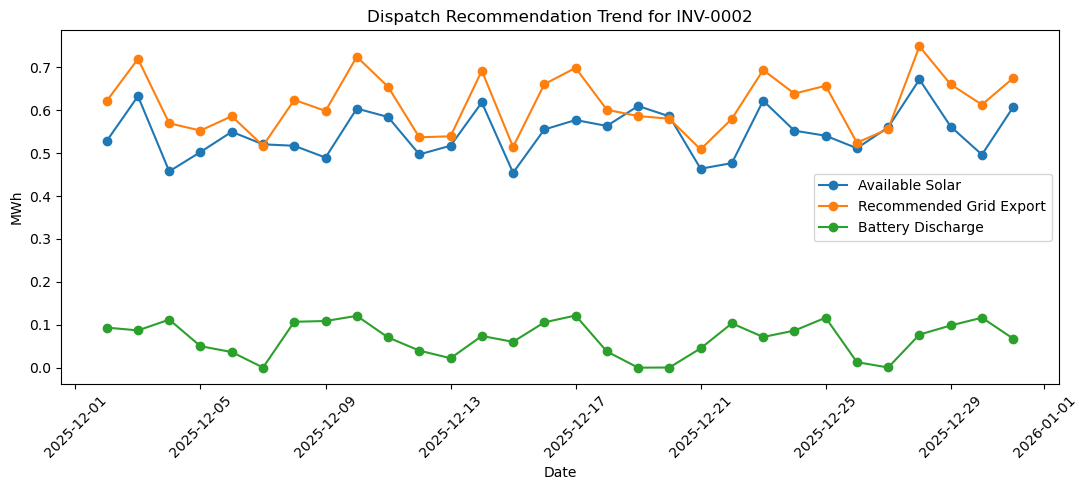

In [27]:
example_inverter = recommendations["inverter_id"].value_counts().index[0]
example_schedule = recommendations[recommendations["inverter_id"] == example_inverter].copy().tail(30)

print("Example inverter:", example_inverter)
display(example_schedule[[
    "date", "available_solar_mwh", "market_price_aud_mwh",
    "model_charge_mwh", "model_discharge_mwh", "model_grid_export_mwh",
    "model_curtailment_mwh", "risk_level", "recommended_action"
]])

plt.figure(figsize=(11, 5))
plt.plot(example_schedule["date"], example_schedule["available_solar_mwh"], marker="o", label="Available Solar")
plt.plot(example_schedule["date"], example_schedule["model_grid_export_mwh"], marker="o", label="Recommended Grid Export")
plt.plot(example_schedule["date"], example_schedule["model_discharge_mwh"], marker="o", label="Battery Discharge")
plt.title(f"Dispatch Recommendation Trend for {example_inverter}")
plt.xlabel("Date")
plt.ylabel("MWh")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

## 20. Scenario Testing Function
This function lets you override market price, grid stress, or available solar to test how the model responds.

In [28]:
def run_dispatch_scenario(row_index: int, price_override=None, grid_stress_override=None, available_solar_override=None):
    """Run a what-if dispatch scenario using one test row."""
    scenario = test_context.iloc[[row_index]].copy()

    if price_override is not None:
        scenario["market_price_aud_mwh"] = price_override
    if grid_stress_override is not None:
        scenario["grid_stress_score"] = grid_stress_override
    if available_solar_override is not None:
        scenario["available_solar_mwh"] = available_solar_override

    scenario_X = scenario[feature_columns]
    raw_pred = dispatch_model.predict(scenario_X)
    feasible_policy = evaluate_predicted_policy(scenario.reset_index(drop=True), raw_pred)
    rt_flag = rt_classifier.predict(scenario_X)[0]

    result = pd.concat([
        scenario[[
            "date", "inverter_id", "available_solar_mwh", "market_price_aud_mwh",
            "grid_stress_score", "failure_risk_score", "grid_export_limit_mwh",
            "initial_soc_mwh", "battery_capacity_mwh"
        ]].reset_index(drop=True),
        feasible_policy.reset_index(drop=True)
    ], axis=1)

    result["real_time_adjustment_required"] = int(rt_flag)
    return result

scenario_result = run_dispatch_scenario(row_index=0, price_override=140, grid_stress_override=0.70)
display(scenario_result)

,date,inverter_id,available_solar_mwh,market_price_aud_mwh,grid_stress_score,failure_risk_score,grid_export_limit_mwh,initial_soc_mwh,battery_capacity_mwh,model_charge_mwh,model_discharge_mwh,model_grid_export_mwh,model_curtailment_mwh,model_soc_end_mwh,model_grid_violation,model_revenue_aud,real_time_adjustment_required
0,2025-09-13,INV-0002,0.60938,140,0.7,0.069589,0.801185,0.10778,0.35,0.0,0.045216,0.654596,0.0,0.058632,0,86.144768,0


## 21. Prototype Model Card

### Model Name
DER Dispatch Optimizer v1.0

### Business Objective
Optimize dispatch of distributed solar and battery assets to increase revenue while maintaining grid stability.

### Model Components
1. Baseline dispatch policy for comparison.
2. MPC-style dispatch optimizer to generate feasible optimized labels.
3. Random Forest dispatch policy model to generate fast dispatch recommendations.
4. Real-time adjustment classifier to flag high-risk operational situations.

### Key Inputs
- Inverter capacity
- Operating hours
- Efficiency
- Temperature
- Soiling index
- Voltage ripple
- Harmonic distortion
- Reactive power capability
- Failure-risk indicators
- Battery SOC proxy
- Market price proxy
- Grid export limit proxy

### Key Outputs
- Recommended battery charge MWh
- Recommended battery discharge MWh
- Recommended grid export MWh
- Recommended curtailment MWh
- Expected revenue
- Grid violation flag
- Risk level
- Recommended action

### Limitations
- Battery SOC, market prices, and grid limits are simulated for this prototype.
- The notebook does not implement full SAC/TD3 reinforcement learning because that requires a digital twin.
- The optimizer is suitable for prototype validation, but production deployment should use real SCADA, BMS, market, and grid constraint feeds.

### Recommended Next Steps
1. Replace synthetic price data with actual market operator price feeds.
2. Replace synthetic battery SOC with BMS telemetry.
3. Add real voltage/frequency constraints.
4. Convert the dispatch policy into an API endpoint.
5. Add SHAP explanations and drift monitoring.
6. Test the policy inside a digital twin before production deployment.
7. Expand from daily resolution to 5-minute or 15-minute dispatch intervals.